<a href="https://colab.research.google.com/github/JManuelRG/TranscriptomaAxolotl/blob/main/Recursos/Flujo%20Bioinform%C3%A1tico%20Ajolote.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Recursos de datos del proyecto: regeneración en el ajolote

## A. Datos del ajolote (Axolotl-Omics, Broad Institute; Bryant et al., 2017)

| Recurso | Uso en el proyecto | Enlace |
|---|---|---|
| Portal Axolotl-Omics | Página de origen de todos los archivos | https://portals.broadinstitute.org/axolotlomics/ |2
| Conteos por gen con anotación | **Dataset principal** (PyDESeq2) | https://data.broadinstitute.org/Trinity/SalamanderWeb/Axo.rsem.genes.counts.wAnnot.matrix.gz |
| Conteos por gen sin anotación | Alternativa ligera | https://data.broadinstitute.org/Trinity/SalamanderWeb/Axo.rsem.genes.counts.matrix.gz |
| FPKM por gen con anotación | Heatmaps | https://data.broadinstitute.org/Trinity/SalamanderWeb/Axo.rsem.genes.TMM.fpkm.wAnnot.matrix.gz |
| Anotación funcional (Trinotate) | Símbolos de genes y GO | https://data.broadinstitute.org/Trinity/SalamanderWeb/Axolotl.Trinity.CellReports2017.Trinotate.xls.gz |
| Proteínas predichas (TransDecoder) | Parte comparativa | https://data.broadinstitute.org/Trinity/SalamanderWeb/Axolotl.Trinity.CellReports2017.transdecoder.pep.gz |
| Transcriptoma ensamblado (FASTA) | Referencia (archivo pesado) | https://data.broadinstitute.org/Trinity/SalamanderWeb/Axolotl.Trinity.CellReports2017.fasta.gz |
| Heatmap interactivo: genes enriquecidos en blastema | Contraste de resultados | https://portals.broadinstitute.org/axolotlomics/morpheus.blastema_enriched.html |
| Heatmap interactivo: genes enriquecidos por tejido | Contraste de resultados | https://portals.broadinstitute.org/axolotlomics/morpheus.tissue_enriched.html |
| Registro GEO del estudio (GSE92429) | Referencia de las muestras | https://www.omicsdi.org/dataset/geo/GSE92429 |

## B. Genomas del ajolote (solo referencia; no se descargan en Colab)

| Ensamblaje | Detalle | Enlace |
|---|---|---|
| GCA_002915635.3 (AmbMex60DD) | Ensamblaje cromosómico, ~28.2 Gb (UCSC GenArk) | https://hgdownload.soe.ucsc.edu/hubs/GCA/002/915/635/GCA_002915635.3/html/GCA_002915635.3_AmbMex60DD.description.html |
| Directorio de descarga GenArk | Archivos del ensamblaje (muy pesado) | https://hgdownload.soe.ucsc.edu/hubs/GCA/002/915/635/GCA_002915635.3/ |
| Amex_PQ.v4 (Smith et al., 2019) | 14 cromosomas, GCA_002915635.2 | https://pmc.ncbi.nlm.nih.gov/articles/PMC6360810 |
| AmexG_v6 y otros ensamblajes | Genome hubs y BLAST (Ambystoma Genetic Stock Center) | https://ambystoma.uky.edu/genome-resources |

## C. Proteomas de especies comparativas (UniProt)

| Especie | ID de proteoma | Enlace |
|---|---|---|
| Humano (*Homo sapiens*) | UP000005640 | https://www.uniprot.org/proteomes/UP000005640 |
| Ratón (*Mus musculus*) | UP000000589 | https://www.uniprot.org/proteomes/UP000000589 |
| Pez cebra (*Danio rerio*) | UP000000437 | https://www.uniprot.org/proteomes/UP000000437 |
| *Xenopus tropicalis* | UP000008143 | https://www.uniprot.org/proteomes/UP000008143 |
| FASTA de proteomas de referencia (EBI, FTP) | Verificar que estén las 4 especies | https://ftp.ebi.ac.uk/pub/databases/reference_proteomes/QfO |

## D. Artículos de referencia

| Artículo | Enlace |
|---|---|
| Bryant et al. (2017), Cell Reports: transcriptoma del ajolote | https://doaj.org/article/1952cf1abfac437ca3a57a2785b1e578 |
| Leigh et al. (2018), Nat. Commun.: blastema a resolución de célula única | https://www.ncbi.nlm.nih.gov/pmc/articles/PMC6279788/ |
| Smith et al. (2019), Genome Res.: genoma cromosómico | https://pmc.ncbi.nlm.nih.gov/articles/PMC6360810 |
| Reanálisis integrado, Sci. Rep. (2019) | https://www.nature.com/articles/s41598-019-56829-6.pdf |


In [ ]:
print("Tamaños")

base = "https://data.broadinstitute.org/Trinity/SalamanderWeb/"
archivos = {
    "conteos_genes_anot":  "Axo.rsem.genes.counts.wAnnot.matrix.gz",
    "conteos_genes":       "Axo.rsem.genes.counts.matrix.gz",
    "fpkm_genes_anot":     "Axo.rsem.genes.TMM.fpkm.wAnnot.matrix.gz",
    "trinotate":           "Axolotl.Trinity.CellReports2017.Trinotate.xls.gz",
    "proteinas":           "Axolotl.Trinity.CellReports2017.transdecoder.pep.gz",
    "transcriptoma_fasta": "Axolotl.Trinity.CellReports2017.fasta.gz",
}

import subprocess, re
for k, f in archivos.items():
    out = subprocess.run(["curl", "-sIL", base + f], capture_output=True, text=True).stdout
    m = re.findall(r"(?i)content-length:\s*(\d+)", out)
    tam = int(m[-1]) / 1e6 if m else None
    print(f"{k:22s} {'%.1f MB' % tam if tam else 'tamaño no informado'}")

Tamaños
conteos_genes_anot     20.7 MB
conteos_genes          19.3 MB
fpkm_genes_anot        28.1 MB
trinotate              28.1 MB
proteinas              26.0 MB
transcriptoma_fasta    268.4 MB


In [ ]:
import pandas as pd
import os

if 'destino' not in globals():
    destino = "/content/drive/MyDrive/proyecto_ajolote/datos"

ruta_archivo = os.path.join(destino, "Axo.rsem.genes.counts.wAnnot.matrix.gz")

# Cargar las primeras filas para visualizar la estructura del archivo
df_visualizacion = pd.read_csv(ruta_archivo, sep="\t", index_col=0, compression="gzip", nrows=20)

print("Vista previa de las primeras 10 filas del dataset de conteos de genes:")
display(df_visualizacion)

Vista previa de las primeras 10 filas del dataset de conteos de genes:


,heart_909_CCGTCC,heart_907_AGTTCC,Testes_253_AR007_CAGATC,hand_10327_CCGTCC,CartWrist_263_AR018_GTCCGC,Ovaries_219_AR018_GTCCGC,heart_908_ATGTCA,distal_GCCAAT_L006,hand_10320_CGATGT,Testes_250_AR002_CGATGT,...,distal_CGATGT_L008,Ovaries_220_AR019_GTGAAA,Embryos,proximal_TGACCA_L008,CartWrist_261_AR007_CAGATC,Bone_257_AR012_CTTGTA,blood_vessel_904_CAGATC,elbow_10328_GTCCGC,Testes_251_AR004_TGACCA,CartLong_258_AR002_CGATGT
c838007_g2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
c1317785_g1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
c1116900_g1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
c1594642_g1,0.0,1.0,2.0,0.0,0.0,5.0,0.0,1.0,1.0,0.0,...,0.0,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
c79807_g1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
c251429_g1,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
c974892_g1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
c16043_g1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
c1756462_g1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
c933507_g1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
import os, subprocess, pandas as pd

# Usamos la variable global 'destino' configurada previamente (Drive o local según corresponda)
# En caso de no estar definida, usamos la ruta de Drive por defecto
if 'destino' not in globals():
    destino = "/content/drive/MyDrive/proyecto_ajolote/datos"

print(f"Verificando archivos en: {destino}\n")

# 1. Ver archivos y tamaños
for f in sorted(os.listdir(destino)):
    print(f"{f:60s} {os.path.getsize(os.path.join(destino, f))/1e6:6.1f} MB")

# 2. Verificar que no estén corruptos
print("\nVerificando integridad con gzip:")
for f in os.listdir(destino):
    if f.endswith('.gz'):
        r = subprocess.run(["gzip", "-t", os.path.join(destino, f)], capture_output=True)
        print(f"{f[:45]:45s} -> {'OK' if r.returncode == 0 else 'CORRUPTO'}")

Verificando archivos en: /content/drive/MyDrive/proyecto_ajolote/datos

Axo.rsem.genes.counts.wAnnot.matrix.gz                         20.7 MB
Axolotl.Trinity.CellReports2017.Trinotate.xls.gz               28.1 MB
Axolotl.Trinity.CellReports2017.transdecoder.pep.gz            26.0 MB

Verificando integridad con gzip:
Axolotl.Trinity.CellReports2017.transdecoder. -> OK
Axolotl.Trinity.CellReports2017.Trinotate.xls -> OK
Axo.rsem.genes.counts.wAnnot.matrix.gz        -> OK


Matriz completa: (1388798, 42)
Ejemplo de IDs: ['c838007_g2', 'c1317785_g1', 'c1116900_g1']

Muestras por grupo:
condicion
blastema               4
extremidad_intacta    10
dtype: int64

Genes: 1,388,798 -> 37,199


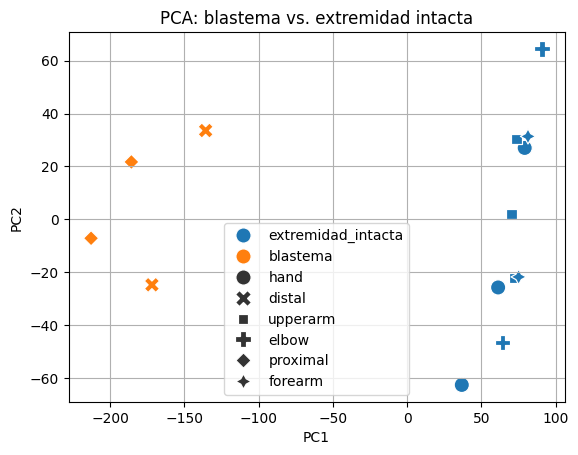

In [ ]:
# Celda: cargar, grupos, filtro y PCA
import numpy as np, pandas as pd, os
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA

destino = "/content/drive/MyDrive/proyecto_ajolote/datos"
salida  = "/content/drive/MyDrive/proyecto_ajolote/resultados"
os.makedirs(salida, exist_ok=True)

# 1. Cargar la matriz
ruta = f"{destino}/Axo.rsem.genes.counts.wAnnot.matrix.gz"
df = pd.read_csv(ruta, sep="\t", index_col=0, compression="gzip")
print("Matriz completa:", df.shape)
print("Ejemplo de IDs:", df.index[:3].tolist())

# 2. Definir grupos
def grupo(c):
    if c.startswith(("distal_", "proximal_")): return "blastema"
    if c.startswith(("hand_", "forearm_", "elbow_", "upperarm_")): return "extremidad_intacta"
    return None

meta = pd.DataFrame({"condicion": [grupo(c) for c in df.columns]}, index=df.columns)
meta["posicion"] = [c.split("_")[0] for c in df.columns]
meta = meta.dropna(subset=["condicion"])
print("\nMuestras por grupo:")
print(meta.groupby("condicion").size())

# 3. Subconjunto, enteros y filtro (>=10 cuentas en al menos 4 muestras)
cnt = df[meta.index].round().astype(int)
antes = cnt.shape[0]
cnt = cnt[(cnt >= 10).sum(axis=1) >= 4]
print(f"\nGenes: {antes:,} -> {cnt.shape[0]:,}")
del df   # libera memoria

# 4. Guardar lo filtrado en Drive
cnt.to_csv(f"{salida}/conteos_filtrados.csv.gz", compression="gzip")
meta.to_csv(f"{salida}/metadatos.csv")

# 5. PCA de verificación (log2 CPM)
cpm = cnt.div(cnt.sum(axis=0), axis=1) * 1e6
pcs = PCA(2).fit_transform(np.log2(cpm + 1).T)
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1],
                hue=meta["condicion"].values, style=meta["posicion"].values, s=120)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA: blastema vs. extremidad intacta")
plt.savefig(f"{salida}/01_pca.png", dpi=300, bbox_inches="tight")
plt.grid()
plt.show()

In [ ]:
# Expresion Diferencial con PyDeSeq2
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

print("pandas:", pd.__version__)

salida = "/content/drive/MyDrive/proyecto_ajolote/resultados"
cnt  = pd.read_csv(f"{salida}/conteos_filtrados.csv.gz", index_col=0)
meta = pd.read_csv(f"{salida}/metadatos.csv", index_col=0)

try:
    dds = DeseqDataSet(counts=cnt.T, metadata=meta[["condicion"]], design="~condicion")
except TypeError:
    dds = DeseqDataSet(counts=cnt.T, metadata=meta[["condicion"]], design_factors="condicion")

dds.deseq2()

st = DeseqStats(dds, contrast=["condicion", "blastema", "extremidad_intacta"])
st.summary()
res = st.results_df.dropna(subset=["padj"])
res.to_csv(f"{salida}/resultados_DE.csv")

sig = res[(res["padj"] < 0.05) & (res["log2FoldChange"].abs() > 1)]
print(f"\nGenes evaluados: {len(res):,}")
print(f"Significativos (padj<0.05, |log2FC|>1): {len(sig):,}")
print(f"  Arriba en blastema: {(sig['log2FoldChange'] > 0).sum():,}")
print(f"  Abajo en blastema:  {(sig['log2FoldChange'] < 0).sum():,}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
pandas: 2.3.3


/usr/local/lib/python3.13/dist-packages/pydeseq2/dds.py:733: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)


Log2 fold change & Wald test p-value: condicion blastema vs extremidad_intacta
                                                      baseMean  \
c1063644_g1^sp|P23768|GAT1B_XENLA                    38.718301   
c1076822_g2^sp|P59644|PI5PA_MOUSE^sp|Q9JMC1|PI5...   14.082749   
c1073808_g2^sp|Q91285|FGFR1_PLEWA^sigP^Tm1          722.735309   
c1070156_g2^sp|Q3KQ23|UBA5_XENLA^sp|Q9GZZ9|UBA5...  234.528835   
c1078531_g1                                          15.455585   
...                                                        ...   
c1084814_g1^sp|Q8TD17|ZN398_HUMAN                   650.505843   
c1085871_g4^sp|Q32PH1|CDCA7_BOVIN                   533.303329   
c1029362_g2                                           6.195419   
c1089194_g7                                          12.406343   
c1082342_g1                                           7.575763   

                                                    log2FoldChange     lfcSE  \
c1063644_g1^sp|P23768|GAT1B_XENLA               

In [ ]:
# Nombres controles y umbral estricto

import pandas as pd, numpy as np, re

salida = "/content/drive/MyDrive/proyecto_ajolote/resultados"
res = pd.read_csv(f"{salida}/resultados_DE.csv", index_col=0)

# 1. Extraer nombre de la mejor homología (UniProt) del ID
def nombre(idx):
    m = re.search(r"\^sp\|[^|]+\|([A-Z0-9]+)_([A-Z0-9]+)", idx)
    return (m.group(1), m.group(2)) if m else (None, None)

tmp = res.index.to_series().apply(nombre)
res["simbolo"] = tmp.str[0]
res["especie_hit"] = tmp.str[1]
res["id"] = res.index.str.split("^").str[0]
print(f"Con nombre asignado: {res['simbolo'].notna().sum():,} de {len(res):,}")

# 2. Genes de control (esperados en blastema según el artículo y la literatura)
control = ["KAZD1", "CIRBP", "MSX1", "MSX2", "FGF8", "FGFR1", "SHH",
           "LN28A", "LN28B", "SOX2", "PAX7", "MMP9"]
cols = ["id", "simbolo", "especie_hit", "baseMean", "log2FoldChange", "padj"]
print("\n=== Genes de control ===")
print(res[res["simbolo"].isin(control)].sort_values("padj")[cols].to_string(index=False))

# 3. Umbral estricto
fuerte = res[(res["padj"] < 0.001) & (res["log2FoldChange"].abs() > 2) & (res["baseMean"] >= 50)]
print(f"\nUmbral estricto (padj<0.001, |log2FC|>2, baseMean>=50): {len(fuerte):,}")
print(f"  Arriba: {(fuerte['log2FoldChange']>0).sum():,}   Abajo: {(fuerte['log2FoldChange']<0).sum():,}")

# 4. Top 15 arriba en blastema (solo los que tienen nombre)
top = fuerte[fuerte["simbolo"].notna()].sort_values("log2FoldChange", ascending=False).head(15)
print("\n=== Top 15 arriba en blastema ===")
print(top[cols].to_string(index=False))

res.to_csv(f"{salida}/resultados_DE_anotados.csv")

Con nombre asignado: 19,609 de 37,009

=== Genes de control ===
         id simbolo especie_hit     baseMean  log2FoldChange          padj
c1076561_g4   KAZD1       MOUSE  2582.422770       10.502765 3.060227e-115
c1071301_g2    FGF8       CHICK    72.226867        5.914150  3.599711e-28
c1076695_g1     SHH       CYNPY    29.878693        7.633282  1.846153e-16
c1091014_g1   CIRBP       LITCT 23292.258051        0.881957  6.471498e-16
c1090351_g5   CIRBP       PONAB  1889.158854        1.786596  6.636844e-11
c1076841_g4   KAZD1       MOUSE    94.734846        2.088562  1.810509e-10
c1076695_g2     SHH       CHICK    10.992626        7.067215  5.283163e-10
c1087157_g3    PAX7       MOUSE    66.572175        2.741997  4.803300e-09
c1073808_g2   FGFR1       PLEWA   722.735309        1.833680  3.303529e-08
c1073808_g4   FGFR1       CHICK     2.497423        3.257638  1.007295e-05
c1073581_g1   CIRBP         RAT 23567.350276        0.530336  8.692701e-02
c1084387_g1   KAZD1       MOUSE    7


MSX1: 0 entradas

MSX2: 0 entradas

LN28A: 0 entradas

LN28B: 0 entradas

MMP9: 1 entradas
         id   baseMean  log2FoldChange     padj
c1065306_g2 745.083428        0.036483 0.948792

PRRX1: 1 entradas
         id   baseMean  log2FoldChange         padj
c1067048_g2 990.032566        3.645266 7.564040e-22

TBX5: 1 entradas
         id    baseMean  log2FoldChange         padj
c1090571_g2 1659.082766        4.500514 7.979898e-41

HAND2: 1 entradas
         id  baseMean  log2FoldChange         padj
c1059102_g5 525.87403        5.855544 1.188097e-35

 c1089371_g1^sp|P80663|FSHB_STRCA^sp|P01225|FSHB_HUMAN^sigP^Tm1

 c1062836_g4^sp|Q9XSW9|LEP_SMICR^sp|O02720|LEP_CANFA^sigP

 c1076552_g2^sp|O42148|OAZ1_CHICK

 c1083574_g1^sp|O15943|CADN_DROME^sigP^Tm1

 c1079702_g1^sp|P14381|YTX2_XENLA^sp|Q9NUD5|ZCHC3_HUMAN^Tm3


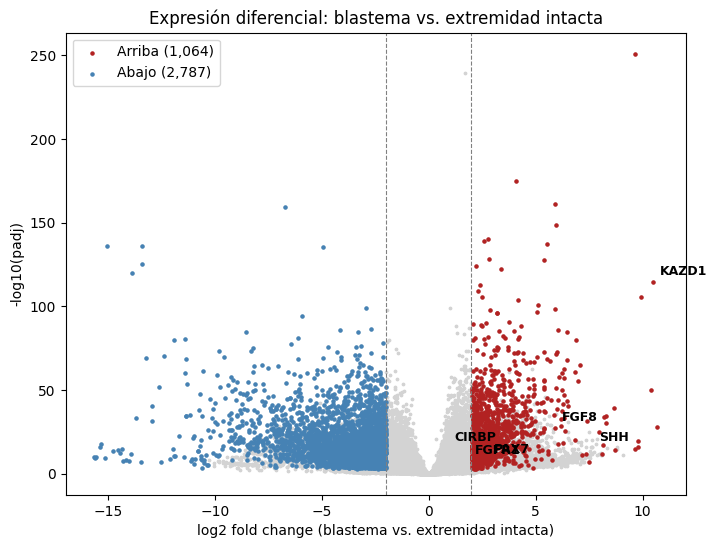

In [ ]:
# Buscar ausentes, revisar sospechosos, generar volcano
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

salida = "/content/drive/MyDrive/proyecto_ajolote/resultados"
res = pd.read_csv(f"{salida}/resultados_DE_anotados.csv", index_col=0)

# 1. Buscar controles en TODOS los hits del ID, no solo el primero
for g in ["MSX1", "MSX2", "LN28A", "LN28B", "MMP9", "PRRX1", "TBX5", "HAND2"]:
    m = res[res.index.str.contains(rf"\|{g}_", regex=True)]
    print(f"\n{g}: {len(m)} entradas")
    if len(m):
        print(m[["id", "baseMean", "log2FoldChange", "padj"]]
              .sort_values("padj").head(3).to_string(index=False))

# 2. Ver los hits completos de los genes sospechosos
for gid in ["c1089371_g1", "c1062836_g4", "c1076552_g2", "c1083574_g1", "c1079702_g1"]:
    fila = res[res["id"] == gid]
    if len(fila):
        print("\n", fila.index[0])

# 3. Volcano plot con controles marcados
res["nlp"] = -np.log10(res["padj"].clip(lower=1e-300))
up   = (res["padj"] < 0.001) & (res["log2FoldChange"] > 2)  & (res["baseMean"] >= 50)
down = (res["padj"] < 0.001) & (res["log2FoldChange"] < -2) & (res["baseMean"] >= 50)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(res["log2FoldChange"], res["nlp"], s=3, c="lightgrey")
ax.scatter(res.loc[up, "log2FoldChange"],   res.loc[up, "nlp"],   s=5, c="firebrick",  label=f"Arriba ({up.sum():,})")
ax.scatter(res.loc[down, "log2FoldChange"], res.loc[down, "nlp"], s=5, c="steelblue", label=f"Abajo ({down.sum():,})")

for s in ["KAZD1", "CIRBP", "FGF8", "SHH", "FGFR1", "PAX7"]:
    sub = res[res["simbolo"] == s].sort_values("padj")
    if len(sub):
        r0 = sub.iloc[0]
        ax.annotate(s, (r0["log2FoldChange"], r0["nlp"]), fontsize=9, fontweight="bold",
                    xytext=(5, 5), textcoords="offset points")

ax.axvline(-2, ls="--", c="grey", lw=0.8); ax.axvline(2, ls="--", c="grey", lw=0.8)
ax.set_xlabel("log2 fold change (blastema vs. extremidad intacta)")
ax.set_ylabel("-log10(padj)")
ax.set_title("Expresión diferencial: blastema vs. extremidad intacta")
ax.legend()
plt.savefig(f"{salida}/02_volcano.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# --- Celda 1 (sesión nueva) ---
!pip install gseapy -q

In [ ]:
# --- Celda 2 ---
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np, io, requests

salida = "/content/drive/MyDrive/proyecto_ajolote/resultados"
res = pd.read_csv(f"{salida}/resultados_DE_anotados.csv", index_col=0)

# 1. Primera accesión de UniProt de cada ID
res["acc"] = res.index.to_series().str.extract(r"\^sp\|([A-Z0-9]+)\|")[0]
accs = res["acc"].dropna().unique().tolist()
print(len(accs), "accesiones únicas")

# 2. Convertir accesión -> símbolo de gen (UniProt, en lotes)
def consulta(lote):
    q = "(" + " OR ".join(f"accession:{a}" for a in lote) + ")"
    r = requests.get("https://rest.uniprot.org/uniprotkb/search",
                     params={"query": q, "fields": "accession,gene_primary",
                             "format": "tsv", "size": 500}, timeout=60)
    r.raise_for_status()
    return pd.read_csv(io.StringIO(r.text), sep="\t")

partes = []
for i in range(0, len(accs), 100):
    try:
        partes.append(consulta(accs[i:i+100]))
    except Exception as e:
        print("Lote fallido", i, e)
tabla = pd.concat(partes)
tabla.columns = ["acc", "gen"]
tabla = tabla.dropna().drop_duplicates("acc")

res = res.join(tabla.set_index("acc"), on="acc")
res["gen"] = res["gen"].str.upper()
print("Con símbolo de gen:", res["gen"].notna().sum(), "de", len(res))

# 3. Un solo registro por gen (el más significativo)
g = res.dropna(subset=["gen"]).sort_values("padj").drop_duplicates("gen")
print("Genes únicos con símbolo:", len(g))

fuerte = (g["padj"] < 0.001) & (g["baseMean"] >= 50)
arriba = g[fuerte & (g["log2FoldChange"] > 2)]["gen"].tolist()
abajo  = g[fuerte & (g["log2FoldChange"] < -2)]["gen"].tolist()
fondo  = g["gen"].tolist()
print("Listas -> arriba:", len(arriba), " abajo:", len(abajo))

res.to_csv(f"{salida}/resultados_DE_simbolos.csv")

# 4. Enriquecimiento
import gseapy as gp
bases = ["GO_Biological_Process_2023", "KEGG_2021_Human"]

for nombre, lista in [("arriba", arriba), ("abajo", abajo)]:
    try:
        enr = gp.enrichr(gene_list=lista, gene_sets=bases, organism="human",
                         background=fondo, outdir=None)
    except Exception as e:
        print("Sin background por:", e)
        enr = gp.enrichr(gene_list=lista, gene_sets=bases, organism="human", outdir=None)
    t = enr.results.sort_values("Adjusted P-value")
    t.to_csv(f"{salida}/enriquecimiento_{nombre}.csv", index=False)
    print(f"\n=== Genes {nombre.upper()} en blastema ===")
    print(t[["Gene_set", "Term", "Overlap", "Adjusted P-value"]].head(12).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
15148 accesiones únicas
Lote fallido 13000 429 Client Error: Too Many Requests for url: https://rest.uniprot.org/uniprotkb/search?query=%28accession%3AQ96S16+OR+accession%3AP59382+OR+accession%3AQ8TE56+OR+accession%3AP86939+OR+accession%3AQ6ZRS4+OR+accession%3AQ6NU94+OR+accession%3AQ8NFU5+OR+accession%3AQ61468+OR+accession%3AQ8C0L0+OR+accession%3AO09118+OR+accession%3AP63100+OR+accession%3AP50754+OR+accession%3AQ9BSD7+OR+accession%3AQ96PD2+OR+accession%3AQ865R1+OR+accession%3AQ8BKS9+OR+accession%3AQ6DED0+OR+accession%3AP32208+OR+accession%3AQ07076+OR+accession%3AQ5F3W3+OR+accession%3AQ52L34+OR+accession%3AQ9Y5Q9+OR+accession%3AQ91Z46+OR+accession%3AP57679+OR+accession%3AQ6P4F7+OR+accession%3AQ54CL2+OR+accession%3AQ86TC9+OR+accession%3AQ8TAG9+OR+accession%3AQ9NV12+OR+accession%3AQ9Y2K6+OR+accession%3AO75592+OR+accession%3AQ02365+OR+accession%3AP07797+OR+access

In [ ]:
#Accesiones intento 2
import pandas as pd, numpy as np, io, requests, time, re

salida = "/content/drive/MyDrive/proyecto_ajolote/resultados"
res = pd.read_csv(f"{salida}/resultados_DE_simbolos.csv", index_col=0)

# 1. Accesiones que aún no tienen símbolo
faltan = res.loc[res["gen"].isna() & res["acc"].notna(), "acc"].unique().tolist()
print(len(faltan), "accesiones por consultar")

URL = "https://rest.uniprot.org/uniprotkb/search"
def consulta(lote, intentos=6):
    q = "(" + " OR ".join(f"accession:{a}" for a in lote) + ")"
    for i in range(intentos):
        r = requests.get(URL, params={"query": q, "fields": "accession,gene_primary",
                                      "format": "tsv", "size": 500}, timeout=60)
        if r.status_code == 429:
            time.sleep(5 * (i + 1))
            continue
        r.raise_for_status()
        return pd.read_csv(io.StringIO(r.text), sep="\t")
    raise RuntimeError("429 persistente")

partes = []
for i in range(0, len(faltan), 100):
    try:
        partes.append(consulta(faltan[i:i+100]))
    except Exception as e:
        print("Lote fallido", i, str(e)[:80])
    time.sleep(1)

if partes:
    nuevo = pd.concat(partes)
    nuevo.columns = ["acc", "gen"]
    nuevo = nuevo.dropna().drop_duplicates("acc").set_index("acc")["gen"].str.upper()
    res["gen"] = res["gen"].fillna(res["acc"].map(nuevo))

print("Con símbolo:", res["gen"].notna().sum(), "de", len(res))
res.to_csv(f"{salida}/resultados_DE_simbolos.csv")

# 2. Un registro por gen (el más significativo) y listas
g = res.dropna(subset=["gen"]).sort_values("padj").drop_duplicates("gen")
fuerte = (g["padj"] < 0.001) & (g["baseMean"] >= 50)
arriba = g[fuerte & (g["log2FoldChange"] > 2)]["gen"].tolist()
abajo  = g[fuerte & (g["log2FoldChange"]

2448 accesiones por consultar
Con símbolo: 18576 de 37009
Genes únicos: 13023 | arriba: 570 | abajo: 1360
Falló GO_Biological_Process_2023 Expecting value: line 1 column 5474 (char 5473)

=== ARRIBA en blastema (con fondo) ===


KeyError: "['Overlap'] not in index"

In [ ]:
# i ntento 3 accesion

import pandas as pd, numpy as np, requests, time
from scipy.stats import hypergeom
from statsmodels.stats.multitest import multipletests

salida = "/content/drive/MyDrive/proyecto_ajolote/resultados"
res = pd.read_csv(f"{salida}/resultados_DE_simbolos.csv", index_col=0)

# 1. Listas y fondo
g = res.dropna(subset=["gen"]).sort_values("padj").drop_duplicates("gen")
fuerte = (g["padj"] < 0.001) & (g["baseMean"] >= 50)
arriba = g[fuerte & (g["log2FoldChange"] > 2)]["gen"].tolist()
abajo  = g[fuerte & (g["log2FoldChange"] < -2)]["gen"].tolist()
fondo  = g["gen"].tolist()
print(f"Fondo: {len(fondo)} | arriba: {len(arriba)} | abajo: {len(abajo)}")

# 2. Descargar biblioteca de Enrichr con reintentos
def bajar_biblioteca(nombre, intentos=5):
    url = "https://maayanlab.cloud/Enrichr/geneSetLibrary"
    texto = None
    for i in range(intentos):
        try:
            r = requests.get(url, params={"mode": "text", "libraryName": nombre}, timeout=120)
            if r.status_code == 200 and "\t" in r.text[:3000]:
                texto = r.text
                break
            print(f"{nombre}: intento {i+1}, status {r.status_code}, {r.text[:80]!r}")
        except Exception as e:
            print(f"{nombre}: intento {i+1}, error {str(e)[:80]}")
        time.sleep(5 * (i + 1))
    if texto is None:
        return None
    lib = {}
    for linea in texto.strip().split("\n"):
        partes = linea.split("\t")
        genes = {x.split(",")[0].strip().upper() for x in partes[2:] if x.strip()}
        if partes[0] and genes:
            lib[partes[0]] = genes
    print(f"{nombre}: {len(lib)} términos")
    return lib

# 3. Prueba hipergeométrica + FDR (BH)
def enriquecer(lista, fondo, lib, k_min=3, K_min=5, K_max=500):
    fondo = set(fondo); lista = set(lista) & fondo
    N, n = len(fondo), len(lista)
    filas = []
    for term, genes in lib.items():
        gs = genes & fondo
        K = len(gs)
        if K < K_min or K > K_max:
            continue
        k = len(lista & gs)
        if k < k_min:
            continue
        p = hypergeom.sf(k - 1, N, K, n)
        filas.append((term, k, K, p, ",".join(sorted(lista & gs))[:300]))
    t = pd.DataFrame(filas, columns=["Term", "k", "K", "p", "Genes"])
    if t.empty:
        return t
    t["padj"] = multipletests(t["p"], method="fdr_bh")[1]
    t["Overlap"] = t["k"].astype(str) + "/" + t["K"].astype(str)
    return t.sort_values("padj")

bibliotecas = ["GO_Biological_Process_2023", "KEGG_2021_Human"]
libs = {b: bajar_biblioteca(b) for b in bibliotecas}

for nombre, lista in [("arriba", arriba), ("abajo", abajo)]:
    tablas = []
    for b, lib in libs.items():
        if lib is None:
            print("No se pudo descargar", b); continue
        t = enriquecer(lista, fondo, lib)
        t.insert(0, "Gene_set", b)
        tablas.append(t)
    if not tablas:
        continue
    t = pd.concat(tablas).sort_values("padj")
    t.to_csv(f"{salida}/enriquecimiento_{nombre}_fondo.csv", index=False)

    print(f"\n=== {nombre.upper()} en blastema (con fondo propio) ===")
    print(t[["Gene_set", "Term", "Overlap", "padj"]].head(12).to_string(index=False))

    pat = r"Wnt|Notch|fibroblast growth|FGF|Hedgehog|cell cycle|proliferation|BMP"
    sub = t[t["Term"].str.contains(pat, case=False, regex=True)].head(8)
    print(f"\n--- Rutas de desarrollo/proliferación en {nombre} ---")
    print(sub[["Term", "Overlap", "padj"]].to_string(index=False) if len(sub) else "Ninguna")

Fondo: 13023 | arriba: 570 | abajo: 1360
GO_Biological_Process_2023: 5407 términos
KEGG_2021_Human: 320 términos

=== ARRIBA en blastema (con fondo propio) ===
                  Gene_set                                                              Term Overlap         padj
GO_Biological_Process_2023                    Extracellular Matrix Organization (GO:0030198)  36/144 3.996005e-15
GO_Biological_Process_2023                 Extracellular Structure Organization (GO:0043062)   23/91 1.676027e-09
GO_Biological_Process_2023        External Encapsulating Structure Organization (GO:0045229)   23/93 1.822991e-09
           KEGG_2021_Human                                          ECM-receptor interaction   18/77 5.469776e-07
GO_Biological_Process_2023                          Skeletal System Development (GO:0001501)  22/120 1.737212e-06
GO_Biological_Process_2023                         Regulation Of Cell Migration (GO:0030334)  40/349 3.326680e-06
GO_Biological_Process_2023                

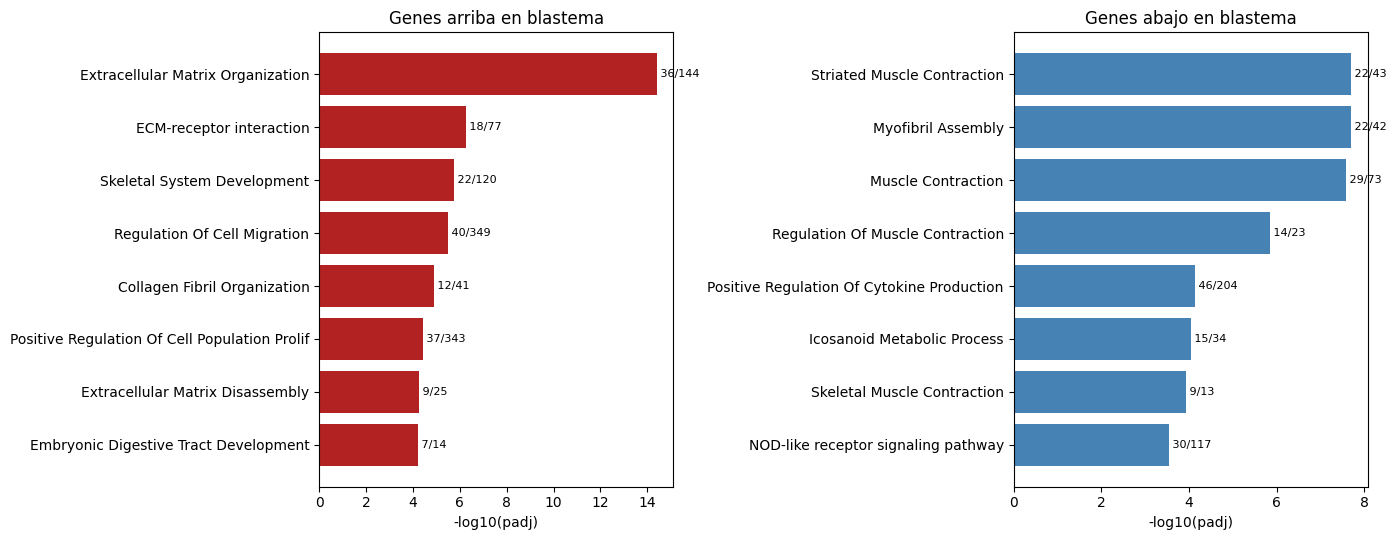

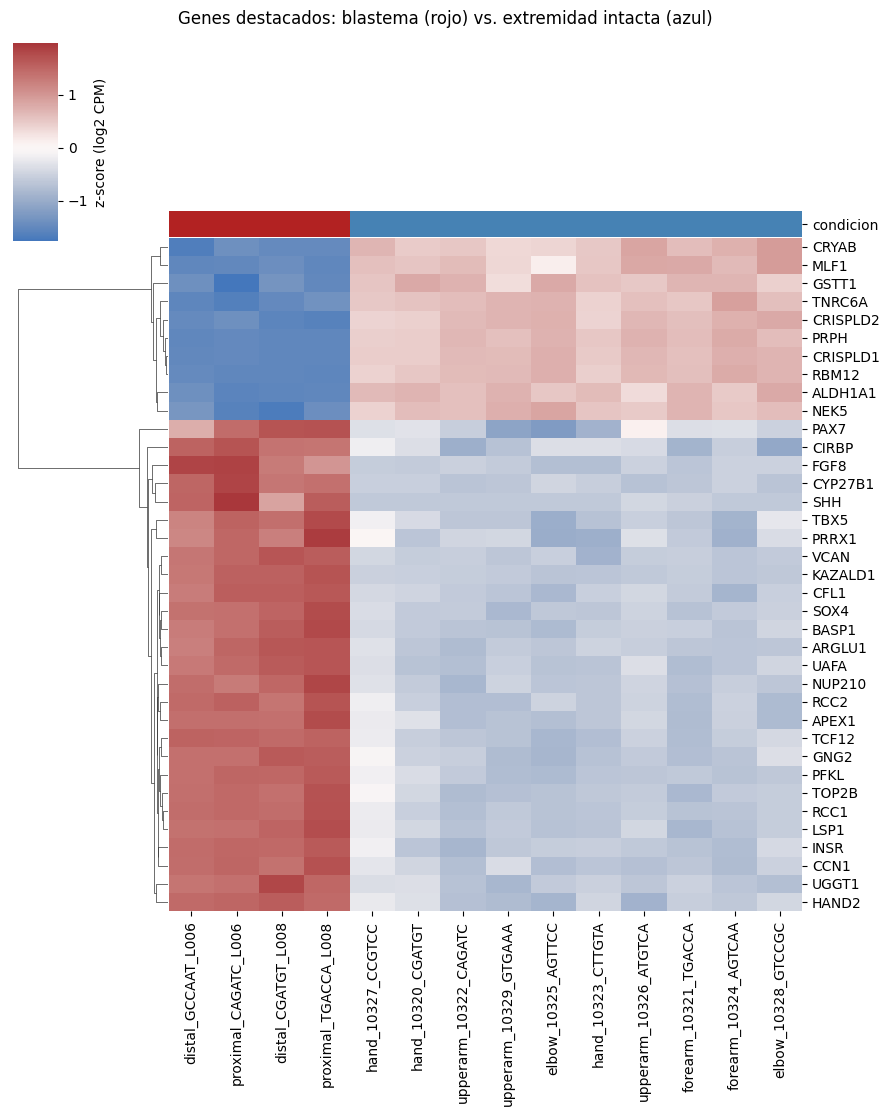

In [ ]:
# Enriquecimieento y heatmap

import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns

salida = "/content/drive/MyDrive/proyecto_ajolote/resultados"

# ---------- FIGURA 3: enriquecimiento sin términos redundantes ----------
def sin_redundancia(t, n=8, umbral=0.5):
    elegidos, conjuntos = [], []
    for _, r in t.sort_values("padj").iterrows():
        gs = set(str(r["Genes"]).split(","))
        if all(len(gs & c) / len(gs | c) < umbral for c in conjuntos):
            elegidos.append(r); conjuntos.append(gs)
        if len(elegidos) == n:
            break
    return pd.DataFrame(elegidos)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (nombre, color) in zip(axes, [("arriba", "firebrick"), ("abajo", "steelblue")]):
    t = pd.read_csv(f"{salida}/enriquecimiento_{nombre}_fondo.csv")
    t = sin_redundancia(t)
    t["etiqueta"] = t["Term"].str.replace(r"\s*\(GO:\d+\)", "", regex=True).str.slice(0, 45)
    t = t.iloc[::-1]
    ax.barh(t["etiqueta"], -np.log10(t["padj"]), color=color)
    for y, (ov, p) in enumerate(zip(t["Overlap"], t["padj"])):
        ax.text(-np.log10(p), y, f" {ov}", va="center", fontsize=8)
    ax.set_xlabel("-log10(padj)")
    ax.set_title(f"Genes {nombre} en blastema")
plt.tight_layout()
plt.savefig(f"{salida}/03_enriquecimiento.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------- FIGURA 4: heatmap ----------
cnt  = pd.read_csv(f"{salida}/conteos_filtrados.csv.gz", index_col=0)
meta = pd.read_csv(f"{salida}/metadatos.csv", index_col=0)
res  = pd.read_csv(f"{salida}/resultados_DE_simbolos.csv", index_col=0)

logc = np.log2(cnt.div(cnt.sum(axis=0), axis=1) * 1e6 + 1)
g = res.dropna(subset=["gen"]).sort_values("padj").drop_duplicates("gen")

base = g[(g["padj"] < 0.001) & (g["baseMean"] >= 200)]
sel_up   = base[base["log2FoldChange"] > 2].head(20)
sel_down = base[base["log2FoldChange"] < -2].head(10)
controles = g[g["gen"].isin(["KAZD1", "CIRBP", "FGF8", "SHH", "PAX7", "PRRX1", "TBX5", "HAND2"])]
sel = pd.concat([sel_up, sel_down, controles]).drop_duplicates("gen")

orden = meta.sort_values("condicion").index
datos = logc.loc[sel.index, orden]
datos.index = sel["gen"].values

colores = meta.loc[orden, "condicion"].map({"blastema": "firebrick", "extremidad_intacta": "steelblue"})
cm = sns.clustermap(datos, z_score=0, cmap="vlag", center=0, col_colors=colores,
                    col_cluster=False, figsize=(9, 11), yticklabels=True,
                    cbar_kws={"label": "z-score (log2 CPM)"})
cm.fig.suptitle("Genes destacados: blastema (rojo) vs. extremidad intacta (azul)", y=1.01)
cm.savefig(f"{salida}/04_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
"""
parte comparativa

Usar tres genes que ya validamos arriba en el análisis: KAZALD1, CIRBP y PRRX1.
un gen del artículo original, uno más moderado y un factor de transcripción muy conservado.

Esta celda busca los IDs en tus resultados, abre el archivo de proteínas,
muestra cómo son los encabezados y extrae la proteína más larga de cada gen.

"""

import pandas as pd, gzip, re

salida  = "/content/drive/MyDrive/proyecto_ajolote/resultados"
destino = "/content/drive/MyDrive/proyecto_ajolote/datos"
res = pd.read_csv(f"{salida}/resultados_DE_simbolos.csv", index_col=0)

# 1. Candidatos por gen (símbolo de UniProt), ordenados por expresión
busca = {"KAZALD1": r"^KAZALD1$|^KAZD1$", "CIRBP": r"^CIRBP$", "PRRX1": r"^PRRX1$"}
cands = {}
for g, pat in busca.items():
    sub = res[res["gen"].fillna("").str.match(pat)].sort_values("baseMean", ascending=False)
    sub = sub.assign(id_gen=sub["id"])
    print(f"\n=== {g} ===")
    print(sub[["id_gen", "baseMean", "log2FoldChange", "padj"]].head(6).to_string(index=False))
    cands[g] = sub["id_gen"].tolist()[:6]

# 2. Cómo son los encabezados del archivo de proteínas
ruta = f"{destino}/Axolotl.Trinity.CellReports2017.transdecoder.pep.gz"
with gzip.open(ruta, "rt") as f:
    n = 0
    for linea in f:
        if linea.startswith(">"):
            print(linea.strip()[:150]); n += 1
            if n == 3: break

# 3. Leer todas las proteínas y agrupar por gen de Trinity
prot = {}
with gzip.open(ruta, "rt") as f:
    nombre, seq = None, []
    for linea in f:
        if linea.startswith(">"):
            if nombre: prot[nombre] = "".join(seq)
            nombre, seq = linea[1:].split()[0], []
        else:
            seq.append(linea.strip())
    if nombre: prot[nombre] = "".join(seq)
print("\nProteínas leídas:", len(prot))

def gen_de(nombre):
    return re.split(r"_i\d+", nombre)[0]

por_gen = {}
for k, s in prot.items():
    por_gen.setdefault(gen_de(k), []).append((k, s))

# 4. Proteína más larga de cada candidato
print("\n=== Proteínas encontradas ===")
for g, ids in cands.items():
    for gid in ids:
        if gid in por_gen:
            k, s = max(por_gen[gid], key=lambda x: len(x[1]))
            print(f"{g:8s} {gid:14s} {k:28s} {len(s)} aa")
        else:
            print(f"{g:8s} {gid:14s} sin proteína en el archivo")


=== KAZALD1 ===
     id_gen    baseMean  log2FoldChange          padj
c1076561_g4 2582.422770       10.502765 3.060227e-115
c1049185_g1  179.086206       -0.044980  8.821460e-01
c1076841_g4   94.734846        2.088562  1.810509e-10
c1084387_g1   75.892150       -0.725491  8.721145e-02

=== CIRBP ===
     id_gen     baseMean  log2FoldChange         padj
c1073581_g1 23567.350276        0.530336 8.692701e-02
c1091014_g1 23292.258051        0.881957 6.471498e-16
c1090351_g5  1889.158854        1.786596 6.636844e-11

=== PRRX1 ===
     id_gen   baseMean  log2FoldChange         padj
c1067048_g2 990.032566        3.645266 7.564040e-22
>cds.c1000017_g1_i1|m.64034 c1000017_g1_i1|g.64034  ORF c1000017_g1_i1|g.64034 c1000017_g1_i1|m.64034 type:5prime_partial len:127 (+) c1000017_g1_i1:2
>cds.c1000017_g2_i2|m.64035 c1000017_g2_i2|g.64035  ORF c1000017_g2_i2|g.64035 c1000017_g2_i2|m.64035 type:3prime_partial len:252 (-) c1000017_g2_i2:1
>cds.c1000023_g1_i2|m.64037 c1000023_g1_i2|g.64037  ORF c1000

In [ ]:
# extraer proteinas del ajolote

import gzip, re, os

destino = "/content/drive/MyDrive/proyecto_ajolote/datos"
salida  = "/content/drive/MyDrive/proyecto_ajolote/resultados"
os.makedirs(f"{salida}/fasta", exist_ok=True)

ruta = f"{destino}/Axolotl.Trinity.CellReports2017.transdecoder.pep.gz"

# 1. Leer proteínas guardando el tipo de ORF
prot = {}
with gzip.open(ruta, "rt") as f:
    nombre, tipo, seq = None, None, []
    for linea in f:
        if linea.startswith(">"):
            if nombre:
                prot[nombre] = ("".join(seq).replace("*", ""), tipo)
            nombre = linea[1:].split()[0]
            m = re.search(r"type:(\w+)", linea)
            tipo = m.group(1) if m else "NA"
            seq = []
        else:
            seq.append(linea.strip())
    if nombre:
        prot[nombre] = ("".join(seq).replace("*", ""), tipo)
print("Proteínas leídas:", len(prot))

# 2. Agrupar por gen de Trinity (quitando el prefijo 'cds.')
por_gen = {}
for k, (s, t) in prot.items():
    m = re.match(r"cds\.(c\d+_g\d+)_i\d+", k)
    if m:
        por_gen.setdefault(m.group(1), []).append((k, s, t))

# 3. Ver todas las isoformas de cada candidato
elegidos = {"KAZALD1": "c1076561_g4", "CIRBP": "c1091014_g1", "PRRX1": "c1067048_g2"}
for g, gid in elegidos.items():
    print(f"\n=== {g} ({gid}) ===")
    for k, s, t in sorted(por_gen.get(gid, []), key=lambda x: -len(x[1])):
        print(f"  {k:32s} {len(s):4d} aa  {t}")

# 4. Elegir: preferir 'complete', luego la más larga
def mejor(lista):
    comp = [x for x in lista if x[2] == "complete"]
    return max(comp or lista, key=lambda x: len(x[1]))

for g, gid in elegidos.items():
    if gid in por_gen:
        k, s, t = mejor(por_gen[gid])
        with open(f"{salida}/fasta/{g}_ajolote.fasta", "w") as out:
            out.write(f">Ajolote|{g}|{k.replace('|', '_')}\n{s}\n")
        print(f"\n{g}: guardada {k} ({len(s)} aa, {t})")
        print(s[:60] + "...")

Proteínas leídas: 196033

=== KAZALD1 (c1076561_g4) ===
  cds.c1076561_g4_i1|m.178512       307 aa  complete
  cds.c1076561_g4_i2|m.178513       102 aa  complete

=== CIRBP (c1091014_g1) ===
  cds.c1091014_g1_i4|m.302117       164 aa  complete
  cds.c1091014_g1_i5|m.302119       164 aa  complete
  cds.c1091014_g1_i2|m.302116       137 aa  complete
  cds.c1091014_g1_i4|m.302118       112 aa  complete
  cds.c1091014_g1_i5|m.302120       112 aa  complete

=== PRRX1 (c1067048_g2) ===
  cds.c1067048_g2_i1|m.127457       272 aa  complete
  cds.c1067048_g2_i2|m.127461       257 aa  complete
  cds.c1067048_g2_i2|m.127462       248 aa  complete
  cds.c1067048_g2_i1|m.127458       219 aa  complete
  cds.c1067048_g2_i2|m.127463       115 aa  5prime_partial

KAZALD1: guardada cds.c1076561_g4_i1|m.178512 (307 aa, complete)
MAVTVSCHLQILATLLLVAMAASFPRRLPFKGWHNLILDSEECSACQVKLCPAVPPSCPA...

CIRBP: guardada cds.c1091014_g1_i4|m.302117 (164 aa, complete)
MSSDEGKIFVGGLSFETTENDLEKEFCKYGKICEVVVIKDRETQRSRGFG

In [ ]:
# ortologos desde uniprot
import requests, time

salida = f"/content/drive/MyDrive/proyecto_ajolote/resultados"
especies = {"Humano": 9606, "Raton": 10090, "PezCebra": 7955, "Xenopus": 8364}
genes = ["KAZALD1", "CIRBP", "PRRX1"]
URL = "https://rest.uniprot.org/uniprotkb/search"

def buscar(gen, taxid, revisado):
    q = f"(gene_exact:{gen}) AND (organism_id:{taxid})"
    if revisado:
        q += " AND (reviewed:true)"
    for i in range(5):
        r = requests.get(URL, params={"query": q, "format": "fasta", "size": 3}, timeout=60)
        if r.status_code == 429:
            time.sleep(5 * (i + 1)); continue
        r.raise_for_status()
        return r.text.strip()
    return ""

for gen in genes:
    registros = []
    for esp, taxid in especies.items():
        txt = buscar(gen, taxid, True) or buscar(gen, taxid, False)
        time.sleep(1)
        if not txt:
            print(f"{gen:8s} {esp:9s} NO ENCONTRADO"); continue
        primero = txt.split(">")[1]
        cab, *lineas = primero.split("\n")
        seq = "".join(lineas)
        acc = cab.split("|")[1]
        print(f"{gen:8s} {esp:9s} {acc:10s} {len(seq):4d} aa  {cab[:70]}")
        registros.append(f">{esp}|{gen}|{acc}\n{seq}\n")
    with open(f"{salida}/fasta/{gen}_ortologos.fasta", "w") as f:
        f.write("".join(registros))

KAZALD1  Humano    Q96I82      304 aa  sp|Q96I82|KAZD1_HUMAN Kazal-type serine protease inhibitor domain-cont
KAZALD1  Raton     Q8BJ66      313 aa  sp|Q8BJ66|KAZD1_MOUSE Kazal-type serine protease inhibitor domain-cont
KAZALD1  PezCebra  NO ENCONTRADO
KAZALD1  Xenopus   A0A8J0Q5X4  299 aa  tr|A0A8J0Q5X4|A0A8J0Q5X4_XENTR Kazal-type serine protease inhibitor do
CIRBP    Humano    Q14011      172 aa  sp|Q14011|CIRBP_HUMAN Cold-inducible RNA-binding protein OS=Homo sapie
CIRBP    Raton     P60824      172 aa  sp|P60824|CIRBP_MOUSE Cold-inducible RNA-binding protein OS=Mus muscul
CIRBP    PezCebra  A0AC58IF21  205 aa  tr|A0AC58IF21|A0AC58IF21_DANRE Cold inducible RNA binding protein b is
CIRBP    Xenopus   Q28IQ9      166 aa  sp|Q28IQ9|CIRBP_XENTR Cold-inducible RNA-binding protein OS=Xenopus tr
PRRX1    Humano    P54821      245 aa  sp|P54821|PRRX1_HUMAN Paired mesoderm homeobox protein 1 OS=Homo sapie
PRRX1    Raton     P63013      245 aa  sp|P63013|PRRX1_MOUSE Paired mesoderm homeobox p

In [ ]:
!pip install Bio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 78.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [Bio]


In [ ]:
!apt-get update
!apt-get install -y mafft
!which mafft && mafft --version

Get:1 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 https://cli.github.com/packages stable InRelease [3,917 B]
Get:4 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:5 http://security.ubuntu.com/ubuntu noble-security/multiverse amd64 Packages [55.6 kB]
Get:6 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2,216 kB]
Get:7 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,560 kB]
Get:8 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,475 kB]
Get:9 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [81.7 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:11 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [60.9 kB]
Get:

In [ ]:
# Alineamiento multiple e identidad  1
!apt-get -qq install mafft > /dev/null 2>&1
!mafft --version

import subprocess, os, re, gzip
from Bio import AlignIO, SeqIO
import pandas as pd, numpy as np

salida  = "/content/drive/MyDrive/proyecto_ajolote/resultados"
destino = "/content/drive/MyDrive/proyecto_ajolote/datos"
os.makedirs(f"{salida}/alineamientos", exist_ok=True)

# 1. Releer proteínas del ajolote si la sesión se reinició
if "prot" not in globals():
    prot = {}
    ruta = f"{destino}/Axolotl.Trinity.CellReports2017.transdecoder.pep.gz"
    with gzip.open(ruta, "rt") as f:
        nombre, tipo, seq = None, None, []
        for linea in f:
            if linea.startswith(">"):
                if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)
                nombre = linea[1:].split()[0]
                m = re.search(r"type:(\w+)", linea); tipo = m.group(1) if m else "NA"
                seq = []
            else:
                seq.append(linea.strip())
        if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)

elegidos = {"KAZALD1": "c1076561_g4", "CIRBP": "c1091014_g1", "PRRX1": "c1067048_g2"}

def identidad(a, b):
    """% de identidad sobre columnas donde ambas secuencias tienen residuo; y cobertura de b."""
    comp = [(x, y) for x, y in zip(a, b) if x != "-" and y != "-"]
    if not comp: return np.nan, 0
    ident = sum(x == y for x, y in comp) / len(comp) * 100
    cob = len(comp) / len(b.replace("-", "")) * 100
    return ident, cob

resumen = []
for gen, gid in elegidos.items():
    recs = []
    # isoformas del ajolote (sin repetir secuencias idénticas)
    vistas = set()
    for k, (s, t) in prot.items():
        m = re.match(r"cds\.(c\d+_g\d+)_i\d+", k)
        if m and m.group(1) == gid and s not in vistas and len(s) >= 80:
            vistas.add(s)
            recs.append((f"Ajolote_{k.split('|')[1]}_{len(s)}aa_{t}", s))
    # ortólogos
    for r in SeqIO.parse(f"{salida}/fasta/{gen}_ortologos.fasta", "fasta"):
        recs.append((r.id.split("|")[0] + "_" + r.id.split("|")[2], str(r.seq)))

    entrada = f"{salida}/alineamientos/{gen}_todas.fasta"
    with open(entrada, "w") as f:
        for n, s in recs: f.write(f">{n}\n{s}\n")

    sal = f"{salida}/alineamientos/{gen}_alineado.fasta"
    with open(sal, "w") as out:
        subprocess.run(["mafft", "--auto", "--quiet", entrada], stdout=out, check=True)

    aln = AlignIO.read(sal, "fasta")
    d = {r.id: str(r.seq) for r in aln}
    ref = next(k for k in d if k.startswith("Humano"))
    print(f"\n=== {gen}: identidad frente a humano ===")
    for k, s in d.items():
        if k == ref: continue
        i, c = identidad(d[ref], s)
        print(f"  {k:48s} identidad {i:5.1f}%   cobertura {c:5.1f}%")
        resumen.append((gen, k, round(i, 1), round(c, 1)))

pd.DataFrame(resumen, columns=["Gen", "Secuencia", "Identidad_%", "Cobertura_%"]) \
  .to_csv(f"{salida}/identidad_vs_humano.csv", index=False)

v7.505 (2022/Apr/10)

=== KAZALD1: identidad frente a humano ===
  Ajolote_m.178512_307aa_complete                  identidad  45.3%   cobertura  94.1%
  Ajolote_m.178513_102aa_complete                  identidad  36.8%   cobertura  85.3%
  Raton_Q8BJ66                                     identidad  84.9%   cobertura  97.1%
  Xenopus_A0A8J0Q5X4                               identidad  65.0%   cobertura  98.3%

=== CIRBP: identidad frente a humano ===
  Ajolote_m.302116_137aa_complete                  identidad  23.1%   cobertura  66.4%
  Ajolote_m.302118_112aa_complete                  identidad  23.1%   cobertura  81.2%
  Ajolote_m.302117_164aa_complete                  identidad  72.0%   cobertura  91.5%
  Raton_P60824                                     identidad  95.3%   cobertura 100.0%
  PezCebra_A0AC58IF21                              identidad  74.8%   cobertura  79.5%
  Xenopus_Q28IQ9                                   identidad  82.2%   cobertura  98.2%

=== PRRX1: identidad f

In [ ]:
# alinear biopython 2
import os, re, gzip
import pandas as pd, numpy as np
from Bio import SeqIO, Align
from Bio.Align import substitution_matrices

salida  = "/content/drive/MyDrive/proyecto_ajolote/resultados"
destino = "/content/drive/MyDrive/proyecto_ajolote/datos"

# 1. Releer proteínas del ajolote si la sesión se reinició
if "prot" not in globals():
    prot = {}
    ruta = f"{destino}/Axolotl.Trinity.CellReports2017.transdecoder.pep.gz"
    with gzip.open(ruta, "rt") as f:
        nombre, tipo, seq = None, None, []
        for linea in f:
            if linea.startswith(">"):
                if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)
                nombre = linea[1:].split()[0]
                m = re.search(r"type:(\w+)", linea); tipo = m.group(1) if m else "NA"
                seq = []
            else:
                seq.append(linea.strip())
        if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)

# 2. Alineador semi-global (no penaliza las diferencias de longitud en los extremos)
al = Align.PairwiseAligner()
al.substitution_matrix = substitution_matrices.load("BLOSUM62")
al.open_gap_score = -10
al.extend_gap_score = -0.5
al.target_end_gap_score = 0
al.query_end_gap_score = 0

def comparar(ref, sec):
    a = al.align(ref, sec)[0]
    cols = matches = 0
    for (t0, t1), (q0, q1) in zip(*a.aligned):
        for x, y in zip(ref[t0:t1], sec[q0:q1]):
            cols += 1
            matches += (x == y)
    ident = 100 * matches / cols if cols else np.nan
    return ident, 100 * cols / len(sec), 100 * cols / len(ref)

elegidos = {"KAZALD1": "c1076561_g4", "CIRBP": "c1091014_g1", "PRRX1": "c1067048_g2"}
filas = []
for gen, gid in elegidos.items():
    ort = {r.id.split("|")[0]: str(r.seq)
           for r in SeqIO.parse(f"{salida}/fasta/{gen}_ortologos.fasta", "fasta")}
    ref = ort["Humano"]

    cands, vistas = [], set()
    for k, (s, t) in prot.items():
        m = re.match(r"cds\.(c\d+_g\d+)_i\d+", k)
        if m and m.group(1) == gid and s not in vistas and len(s) >= 80:
            vistas.add(s); cands.append((f"Ajolote {k.split('|')[1]} ({len(s)} aa, {t})", s))
    cands += [(esp, s) for esp, s in ort.items() if esp != "Humano"]

    print(f"\n=== {gen}: comparación con humano ({len(ref)} aa) ===")
    for nom, s in cands:
        i, cs, cr = comparar(ref, s)
        print(f"  {nom:48s} identidad {i:5.1f}% | cubre {cs:5.1f}% de la secuencia | {cr:5.1f}% de la humana")
        filas.append((gen, nom, round(i, 1), round(cs, 1), round(cr, 1)))

pd.DataFrame(filas, columns=["Gen", "Secuencia", "Identidad_%", "Cobertura_seq_%", "Cobertura_humana_%"]) \
  .to_csv(f"{salida}/identidad_vs_humano.csv", index=False)


/usr/local/lib/python3.13/dist-packages/Bio/Align/__init__.py:4412: BiopythonDeprecationWarning: The attribute 'target_end_gap_score' was renamed to 'end_insertion_score'. This was done to be consistent with the
AlignmentCounts object returned by the .counts method of an Alignment object.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/Bio/Align/__init__.py:4412: BiopythonDeprecationWarning: The attribute 'query_end_gap_score' was renamed to 'end_deletion_score'. This was done to be consistent with the
AlignmentCounts object returned by the .counts method of an Alignment object.
  warnings.warn(



=== KAZALD1: comparación con humano (304 aa) ===
  Ajolote m.178512 (307 aa, complete)              identidad  43.8% | cubre  94.5% de la secuencia |  95.4% de la humana
  Ajolote m.178513 (102 aa, complete)              identidad  35.6% | cubre  85.3% de la secuencia |  28.6% de la humana
  Raton                                            identidad  84.5% | cubre  97.1% de la secuencia | 100.0% de la humana
  Xenopus                                          identidad  65.4% | cubre  99.7% de la secuencia |  98.0% de la humana

=== CIRBP: comparación con humano (172 aa) ===
  Ajolote m.302116 (137 aa, complete)              identidad  30.5% | cubre  59.9% de la secuencia |  47.7% de la humana
  Ajolote m.302118 (112 aa, complete)              identidad  30.5% | cubre  73.2% de la secuencia |  47.7% de la humana
  Ajolote m.302117 (164 aa, complete)              identidad  74.0% | cubre  93.9% de la secuencia |  89.5% de la humana
  Raton                                            iden

In [ ]:
# Celda: verificación CIRBP vs. RBM3, KAZALD1 en pez cebra y secuencias finales
import requests, re, os, gzip, time
import pandas as pd, numpy as np
from Bio import SeqIO, Align
from Bio.Align import substitution_matrices

salida  = "/content/drive/MyDrive/proyecto_ajolote/resultados"
destino = "/content/drive/MyDrive/proyecto_ajolote/datos"

# --- Proteínas del ajolote (por si la sesión se reinició) ---
if "prot" not in globals():
    prot = {}
    with gzip.open(f"{destino}/Axolotl.Trinity.CellReports2017.transdecoder.pep.gz", "rt") as f:
        nombre, tipo, seq = None, None, []
        for linea in f:
            if linea.startswith(">"):
                if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)
                nombre = linea[1:].split()[0]
                m = re.search(r"type:(\w+)", linea); tipo = m.group(1) if m else "NA"
                seq = []
            else:
                seq.append(linea.strip())
        if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)

al = Align.PairwiseAligner()
al.substitution_matrix = substitution_matrices.load("BLOSUM62")
al.open_gap_score, al.extend_gap_score = -10, -0.5
al.target_end_gap_score = al.query_end_gap_score = 0

def ident(ref, sec):
    a = al.align(ref, sec)[0]
    cols = matches = 0
    for (t0, t1), (q0, q1) in zip(*a.aligned):
        for x, y in zip(ref[t0:t1], sec[q0:q1]):
            cols += 1; matches += (x == y)
    return (100 * matches / cols if cols else np.nan), 100 * cols / len(sec)

# --- 1. CIRBP vs RBM3 ---
r = requests.get("https://rest.uniprot.org/uniprotkb/P98179.fasta", timeout=60)
r.raise_for_status()
cab, *lin = r.text.strip().split("\n")
rbm3 = "".join(lin)
print("Referencia RBM3:", cab[:90], f"({len(rbm3)} aa)")   # confirma que sea RBM3 humana

ort = {x.id.split("|")[0]: str(x.seq) for x in SeqIO.parse(f"{salida}/fasta/CIRBP_ortologos.fasta", "fasta")}
cirbp_h = ort["Humano"]

print("\n=== Candidatos del ajolote: ¿se parecen más a CIRBP o a RBM3? ===")
for gid in ["c1091014_g1", "c1090351_g5", "c1073581_g1"]:
    vistas = set()
    for k, (s, t) in prot.items():
        m = re.match(r"cds\.(c\d+_g\d+)_i\d+", k)
        if m and m.group(1) == gid and s not in vistas and len(s) >= 80:
            vistas.add(s)
            ic, _ = ident(cirbp_h, s)
            ir, _ = ident(rbm3, s)
            veredicto = "CIRBP" if ic > ir else "RBM3"
            print(f"  {gid} {k.split('|')[1]:10s} {len(s):4d} aa  vs CIRBP {ic:5.1f}%  vs RBM3 {ir:5.1f}%  -> {veredicto}")

# --- 2. KAZALD1 en pez cebra: búsqueda alternativa ---
print("\n=== KAZALD1 en pez cebra ===")
for q in ['(gene:kazald1) AND (organism_id:7955)',
          '(protein_name:"Kazal-type serine protease inhibitor domain-containing protein 1") AND (organism_id:7955)']:
    rr = requests.get("https://rest.uniprot.org/uniprotkb/search",
                      params={"query": q, "format": "fasta", "size": 3}, timeout=60)
    heads = [l for l in rr.text.split("\n") if l.startswith(">")]
    print(q[:60], "->", heads[:3] if heads else "sin resultados")
    time.sleep(1)

Referencia RBM3: >sp|P98179|RBM3_HUMAN RNA-binding protein 3 OS=Homo sapiens OX=9606 GN=RBM3 PE=1 SV=1 (157 aa)

=== Candidatos del ajolote: ¿se parecen más a CIRBP o a RBM3? ===
  c1091014_g1 m.302116    137 aa  vs CIRBP  30.5%  vs RBM3  34.5%  -> RBM3
  c1091014_g1 m.302118    112 aa  vs CIRBP  30.5%  vs RBM3  34.5%  -> RBM3
  c1091014_g1 m.302117    164 aa  vs CIRBP  74.0%  vs RBM3  66.4%  -> CIRBP
  c1090351_g5 m.295892    166 aa  vs CIRBP  81.8%  vs RBM3  69.4%  -> CIRBP
  c1090351_g5 m.295894    137 aa  vs CIRBP  81.8%  vs RBM3  69.4%  -> CIRBP
  c1090351_g5 m.295896    170 aa  vs CIRBP  67.0%  vs RBM3  61.1%  -> CIRBP
  c1073581_g1 m.159799    124 aa  vs CIRBP  58.3%  vs RBM3  57.1%  -> CIRBP
  c1073581_g1 m.159801    109 aa  vs CIRBP  27.7%  vs RBM3  27.7%  -> RBM3
  c1073581_g1 m.159800    152 aa  vs CIRBP  73.3%  vs RBM3  66.4%  -> CIRBP
  c1073581_g1 m.159802    152 aa  vs CIRBP  72.6%  vs RBM3  65.7%  -> CIRBP
  c1073581_g1 m.159804    177 aa  vs CIRBP  72.6%  vs RBM3  65.7

KAZALD1: 4 secuencias guardadas (ajolote m.178512, 307 aa)
PRRX1: 5 secuencias guardadas (ajolote m.127462, 248 aa)
CIRBP: 5 secuencias guardadas (ajolote m.295892, 166 aa)
RBM3 Humano    ('>sp|P98179|RBM3_HUMAN RNA-binding protein 3 OS=Homo sapiens OX=9606 GN', 157)
RBM3 Raton     ('>sp|O89086|RBM3_MOUSE RNA-binding protein 3 OS=Mus musculus OX=10090 G', 153)
RBM3 PezCebra  NO ENCONTRADO
RBM3 Xenopus   NO ENCONTRADO


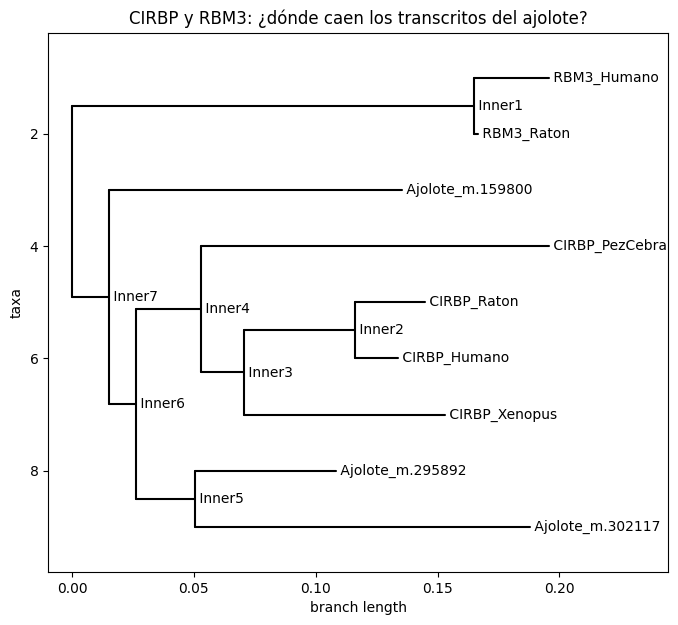

In [ ]:
# arbol filogenetico
import requests, time, subprocess, os, re, gzip
from Bio import SeqIO, AlignIO, Phylo
from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceTreeConstructor
import matplotlib.pyplot as plt

salida  = "/content/drive/MyDrive/proyecto_ajolote/resultados"
destino = "/content/drive/MyDrive/proyecto_ajolote/datos"
os.makedirs(f"{salida}/final", exist_ok=True)

# --- Proteínas del ajolote (por si la sesión se reinició) ---
if "prot" not in globals():
    prot = {}
    with gzip.open(f"{destino}/Axolotl.Trinity.CellReports2017.transdecoder.pep.gz", "rt") as f:
        nombre, tipo, seq = None, None, []
        for linea in f:
            if linea.startswith(">"):
                if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)
                nombre = linea[1:].split()[0]
                m = re.search(r"type:(\w+)", linea); tipo = m.group(1) if m else "NA"
                seq = []
            else:
                seq.append(linea.strip())
        if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)

def por_mid(mid):
    for k, (s, t) in prot.items():
        if k.endswith("|" + mid):
            return k, s
    raise KeyError(mid)

# --- 1. Fijar secuencias finales del panel ---
finales = {"KAZALD1": "m.178512", "PRRX1": "m.127462", "CIRBP": "m.295892"}
for gen, mid in finales.items():
    k, s = por_mid(mid)
    regs = [f">Ajolote|{gen}|{mid}\n{s}\n"]
    for r in SeqIO.parse(f"{salida}/fasta/{gen}_ortologos.fasta", "fasta"):
        regs.append(f">{r.id}\n{r.seq}\n")
    with open(f"{salida}/final/{gen}_final.fasta", "w") as f:
        f.write("".join(regs))
    print(f"{gen}: {len(regs)} secuencias guardadas (ajolote {mid}, {len(s)} aa)")

# --- 2. Descargar RBM3 de cada especie ---
URL = "https://rest.uniprot.org/uniprotkb/search"
def uniprot(gen, taxid):
    for filtro in [" AND (reviewed:true)", ""]:
        q = f"(gene_exact:{gen}) AND (organism_id:{taxid}){filtro}"
        for i in range(5):
            r = requests.get(URL, params={"query": q, "format": "fasta", "size": 1}, timeout=60)
            if r.status_code == 429:
                time.sleep(5 * (i + 1)); continue
            r.raise_for_status(); break
        if r.text.strip():
            cab, *lin = r.text.strip().split("\n")[0:],
            partes = r.text.strip().split("\n")
            return partes[0], "".join(partes[1:])
        time.sleep(1)
    return None, None

especies = {"Humano": 9606, "Raton": 10090, "PezCebra": 7955, "Xenopus": 8364}
rbm3 = {}
for esp, tx in especies.items():
    cab, s = uniprot("RBM3", tx)
    print(f"RBM3 {esp:9s}", (cab[:70], len(s)) if s else "NO ENCONTRADO")
    if s: rbm3[esp] = s

# --- 3. Alineamiento CIRBP + RBM3 + candidatos del ajolote ---
secs = {}
for r in SeqIO.parse(f"{salida}/fasta/CIRBP_ortologos.fasta", "fasta"):
    secs["CIRBP_" + r.id.split("|")[0]] = str(r.seq)
for esp, s in rbm3.items():
    secs["RBM3_" + esp] = s
for mid in ["m.295892", "m.302117", "m.159800"]:
    secs["Ajolote_" + mid] = por_mid(mid)[1]

ent = f"{salida}/final/CIRBP_RBM3.fasta"
with open(ent, "w") as f:
    for n, s in secs.items(): f.write(f">{n}\n{s}\n")
ali = f"{salida}/final/CIRBP_RBM3_alineado.fasta"
with open(ali, "w") as out:
    subprocess.run(["mafft", "--auto", "--quiet", ent], stdout=out, check=True)

# --- 4. Árbol de vecinos más cercanos ---
aln = AlignIO.read(ali, "fasta")
dm = DistanceCalculator("blosum62").get_distance(aln)
arbol = DistanceTreeConstructor().nj(dm)
arbol.root_at_midpoint()

fig, ax = plt.subplots(figsize=(8, 7))
Phylo.draw(arbol, axes=ax, do_show=False)
ax.set_title("CIRBP y RBM3: ¿dónde caen los transcritos del ajolote?")
plt.savefig(f"{salida}/05_arbol_CIRBP_RBM3.png", dpi=300, bbox_inches="tight")
plt.show()

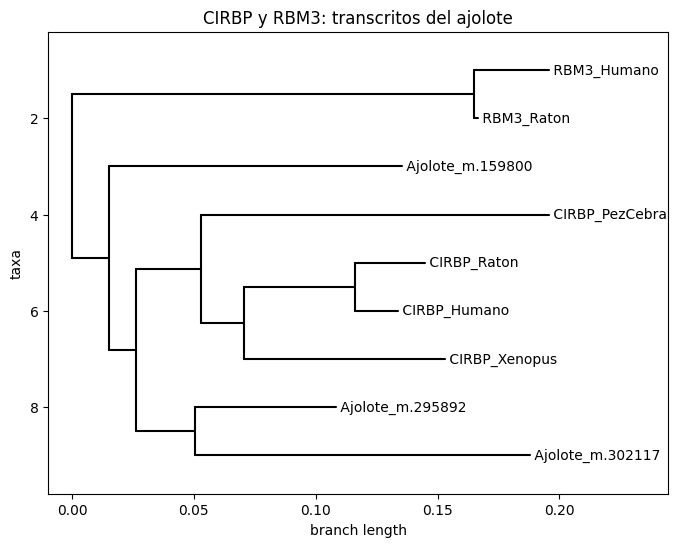

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
Phylo.draw(arbol, axes=ax, do_show=False,
           label_func=lambda c: c.name if c.is_terminal() else None)
ax.set_title("CIRBP y RBM3: transcritos del ajolote")
plt.savefig(f"{salida}/05_arbol_CIRBP_RBM3.png", dpi=300, bbox_inches="tight")

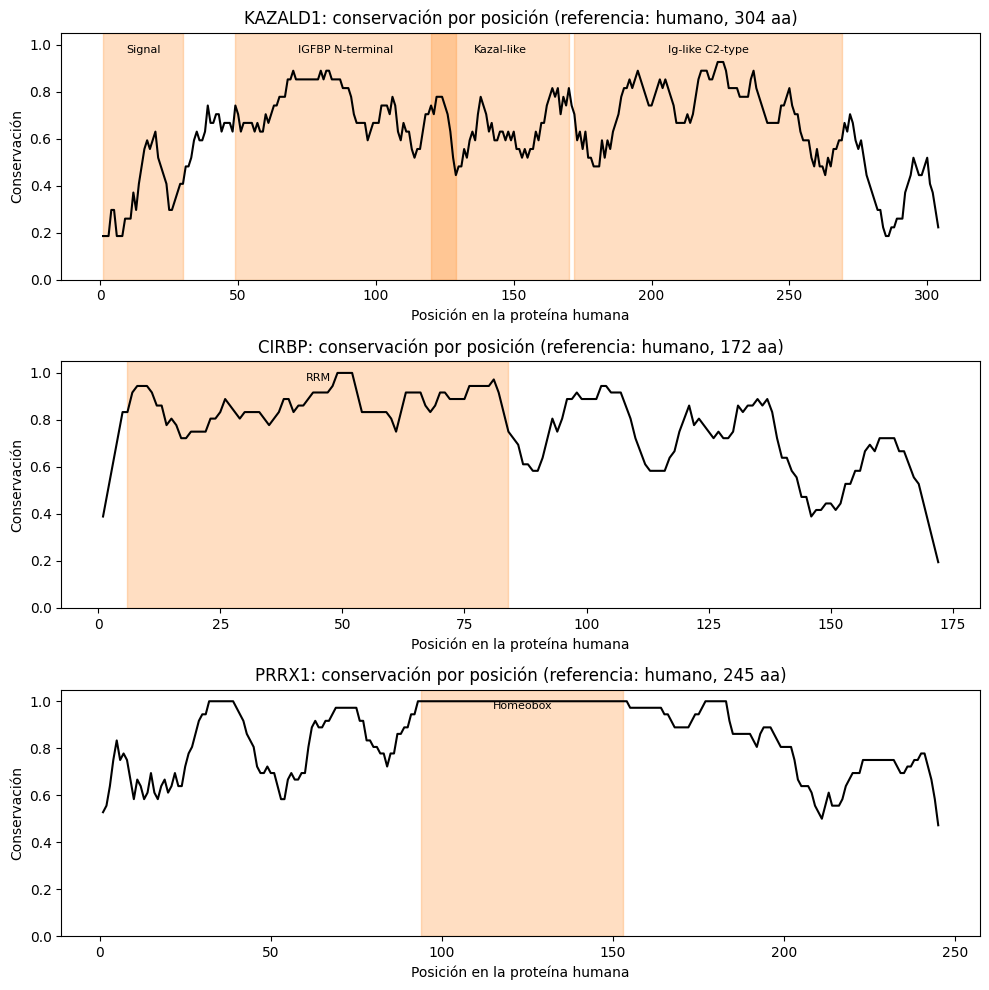

    Gen           Región Posiciones  Identidad_ajolote_%  Cobertura_%
KAZALD1           Signal       1-30                 56.2         53.3
KAZALD1 IGFBP N-terminal     49-129                 55.0         98.8
KAZALD1       Kazal-like    120-170                 47.1        100.0
KAZALD1  Ig-like C2-type    172-269                 49.0        100.0
  CIRBP              RRM       6-84                 86.1        100.0
  PRRX1         Homeobox     94-153                100.0        100.0


In [ ]:
#Siguiente paso: perfil de conservación con dominios
import subprocess, requests, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from Bio import AlignIO

salida = "/content/drive/MyDrive/proyecto_ajolote/resultados"
accs = {"KAZALD1": "Q96I82", "CIRBP": "Q14011", "PRRX1": "P54821"}   # accesiones humanas

def dominios(acc):
    r = requests.get(f"https://rest.uniprot.org/uniprotkb/{acc}.json", timeout=60)
    r.raise_for_status()
    out = []
    for ft in r.json().get("features", []):
        if ft["type"] in ("Domain", "DNA binding", "Signal"):
            ini = ft["location"]["start"]["value"]; fin = ft["location"]["end"]["value"]
            nom = ft.get("description") or ft["type"]
            out.append((nom, ini, fin))
    return out

fig, axes = plt.subplots(3, 1, figsize=(10, 10))
filas = []
for ax, (gen, acc) in zip(axes, accs.items()):
    ent = f"{salida}/final/{gen}_final.fasta"
    ali = f"{salida}/final/{gen}_alineado.fasta"
    with open(ali, "w") as out:
        subprocess.run(["mafft", "--auto", "--quiet", ent], stdout=out, check=True)

    aln = AlignIO.read(ali, "fasta")
    filas_aln = {r.id: str(r.seq) for r in aln}
    hum = next(k for k in filas_aln if k.startswith("Humano"))
    axo = next(k for k in filas_aln if k.startswith("Ajolote"))
    ref, sa = filas_aln[hum], filas_aln[axo]
    otros = [k for k in filas_aln if k != hum]

    cols_h = [i for i, c in enumerate(ref) if c != "-"]        # columnas con residuo humano
    cons = np.array([np.mean([filas_aln[k][i] == ref[i] for k in otros]) for i in cols_h])
    suav = np.convolve(cons, np.ones(9) / 9, mode="same")

    x = np.arange(1, len(cols_h) + 1)
    ax.plot(x, suav, color="black", lw=1.5)
    ax.set_ylim(0, 1.05); ax.set_ylabel("Conservación")
    ax.set_title(f"{gen}: conservación por posición (referencia: humano, {len(cols_h)} aa)")

    for nom, ini, fin in dominios(acc):
        ax.axvspan(ini, fin, alpha=0.25, color="tab:orange")
        ax.text((ini + fin) / 2, 1.0, nom[:22], ha="center", va="top", fontsize=8)
        # identidad del ajolote dentro del dominio
        pos = [cols_h[p] for p in range(ini - 1, min(fin, len(cols_h)))]
        pares = [(ref[i], sa[i]) for i in pos if sa[i] != "-"]
        ident = 100 * np.mean([a == b for a, b in pares]) if pares else np.nan
        filas.append((gen, nom, f"{ini}-{fin}", round(ident, 1), round(100 * len(pares) / len(pos), 1)))
    ax.set_xlabel("Posición en la proteína humana")

plt.tight_layout()
plt.savefig(f"{salida}/06_conservacion.png", dpi=300, bbox_inches="tight")
plt.show()

tabla = pd.DataFrame(filas, columns=["Gen", "Región", "Posiciones", "Identidad_ajolote_%", "Cobertura_%"])
print(tabla.to_string(index=False))
tabla.to_csv(f"{salida}/identidad_por_dominio.csv", index=False)

In [ ]:
#probar otras entradas de kazald 1
import numpy as np, pandas as pd, re, gzip, os
from Bio import AlignIO, SeqIO, Align
from Bio.Align import substitution_matrices

salida  = "/content/drive/MyDrive/proyecto_ajolote/resultados"
destino = "/content/drive/MyDrive/proyecto_ajolote/datos"

# ---- A. Identidad por dominio para TODAS las especies ----
dom = {"KAZALD1": [("IGFBP N-term", 49, 129), ("Kazal-like", 120, 170), ("Ig-like C2", 172, 269)],
       "CIRBP":   [("RRM", 6, 84)],
       "PRRX1":   [("Homeobox", 94, 153)]}
filas = []
for gen, regs in dom.items():
    aln = AlignIO.read(f"{salida}/final/{gen}_alineado.fasta", "fasta")
    d = {r.id: str(r.seq) for r in aln}
    hum = next(k for k in d if k.startswith("Humano")); ref = d[hum]
    cols = [i for i, c in enumerate(ref) if c != "-"]
    for nom, ini, fin in regs:
        pos = cols[ini - 1:fin]
        for k, s in d.items():
            if k == hum: continue
            pares = [(ref[i], s[i]) for i in pos if s[i] != "-"]
            ident = 100 * np.mean([a == b for a, b in pares]) if pares else np.nan
            filas.append((gen, nom, k.split("|")[0], round(ident, 1)))
tabla = pd.DataFrame(filas, columns=["Gen", "Region", "Especie", "Identidad_%"])
print(tabla.pivot_table(index=["Gen", "Region"], columns="Especie", values="Identidad_%").to_string())

# ---- B. Otras entradas de KAZALD1 del ajolote ----
if "prot" not in globals():
    prot = {}
    with gzip.open(f"{destino}/Axolotl.Trinity.CellReports2017.transdecoder.pep.gz", "rt") as f:
        nombre, tipo, seq = None, None, []
        for linea in f:
            if linea.startswith(">"):
                if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)
                nombre = linea[1:].split()[0]
                m = re.search(r"type:(\w+)", linea); tipo = m.group(1) if m else "NA"
                seq = []
            else:
                seq.append(linea.strip())
        if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)

al = Align.PairwiseAligner()
al.substitution_matrix = substitution_matrices.load("BLOSUM62")
al.open_gap_score, al.extend_gap_score = -10, -0.5
al.target_end_gap_score = al.query_end_gap_score = 0

def ident(ref, sec):
    a = al.align(ref, sec)[0]; cols = mt = 0
    for (t0, t1), (q0, q1) in zip(*a.aligned):
        for x, y in zip(ref[t0:t1], sec[q0:q1]):
            cols += 1; mt += (x == y)
    return (100 * mt / cols if cols else np.nan), 100 * cols / len(ref)

ort = {r.id.split("|")[0]: str(r.seq) for r in SeqIO.parse(f"{salida}/fasta/KAZALD1_ortologos.fasta", "fasta")}
hum = ort["Humano"]
print("\n=== Entradas KAZALD1 del ajolote vs humano ===")
for gid in ["c1076561_g4", "c1076841_g4", "c1049185_g1", "c1084387_g1"]:
    vistas = set()
    for k, (s, t) in prot.items():
        m = re.match(r"cds\.(c\d+_g\d+)_i\d+", k)
        if m and m.group(1) == gid and s not in vistas and len(s) >= 80:
            vistas.add(s)
            i, c = ident(hum, s)
            print(f"  {gid} {k.split('|')[1]:10s} {len(s):4d} aa  {t:15s} identidad {i:5.1f}%  cubre {c:5.1f}% de la humana")

Especie               Ajolote  PezCebra  Raton  Xenopus
Gen     Region                                         
CIRBP   RRM              86.1      77.2   98.7     87.3
KAZALD1 IGFBP N-term     55.0       NaN   95.1     71.2
        Ig-like C2       49.0       NaN   88.8     76.5
        Kazal-like       47.1       NaN   88.2     62.7
PRRX1   Homeobox        100.0     100.0  100.0    100.0

=== Entradas KAZALD1 del ajolote vs humano ===


/usr/local/lib/python3.13/dist-packages/Bio/Align/__init__.py:4412: BiopythonDeprecationWarning: The attribute 'target_end_gap_score' was renamed to 'end_insertion_score'. This was done to be consistent with the
AlignmentCounts object returned by the .counts method of an Alignment object.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/Bio/Align/__init__.py:4412: BiopythonDeprecationWarning: The attribute 'query_end_gap_score' was renamed to 'end_deletion_score'. This was done to be consistent with the
AlignmentCounts object returned by the .counts method of an Alignment object.
  warnings.warn(


  c1076561_g4 m.178512    307 aa  complete        identidad  43.8%  cubre  95.4% de la humana
  c1076561_g4 m.178513    102 aa  complete        identidad  35.6%  cubre  28.6% de la humana
  c1076841_g4 m.180419    144 aa  3prime_partial  identidad  31.5%  cubre  29.3% de la humana
  c1076841_g4 m.180417    277 aa  complete        identidad  48.5%  cubre  89.5% de la humana
  c1076841_g4 m.180421    206 aa  complete        identidad  50.7%  cubre  66.1% de la humana
  c1049185_g1 m.90497     230 aa  complete        identidad  63.3%  cubre  75.3% de la humana
  c1049185_g1 m.90498     299 aa  complete        identidad  64.2%  cubre  98.4% de la humana
  c1084387_g1 m.240218    299 aa  complete        identidad  50.9%  cubre  93.1% de la humana
  c1084387_g1 m.240221    108 aa  complete        identidad  30.5%  cubre  31.2% de la humana


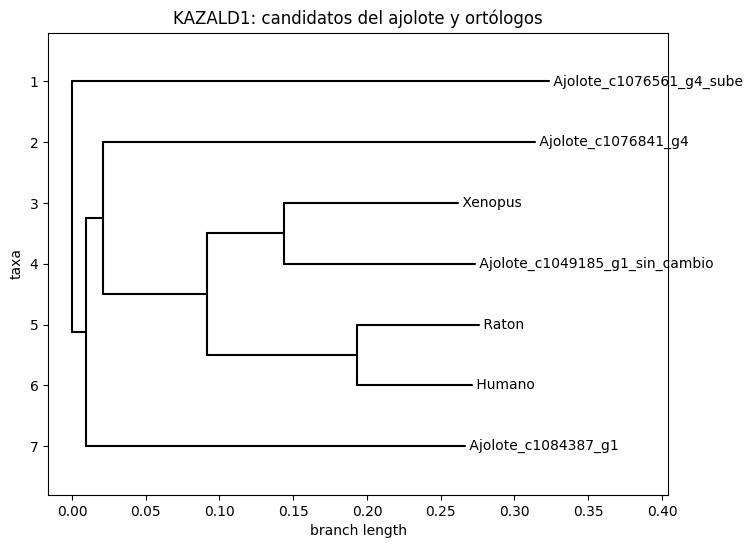


Identidad entre parejas (%):
                                Humano  Raton  Xenopus  Ajolote_c107  Ajolote_c104  Ajolote_c108  Ajolote_c107
Humano                           100.0   85.0     65.0          45.0          65.0          48.0          46.0
Raton                             85.0  100.0     65.0          43.0          64.0          48.0          46.0
Xenopus                           65.0   65.0    100.0          41.0          74.0          51.0          49.0
Ajolote_c1076561_g4_sube          45.0   43.0     41.0         100.0          38.0          41.0          40.0
Ajolote_c1049185_g1_sin_cambio    65.0   64.0     74.0          38.0         100.0          50.0          48.0
Ajolote_c1084387_g1               48.0   48.0     51.0          41.0          50.0         100.0          45.0
Ajolote_c1076841_g4               46.0   46.0     49.0          40.0          48.0          45.0         100.0


In [ ]:
"""
Celda: árbol de las cuatro entradas con ortólogos

Responde si el ajolote tiene un ortólogo claro y qué relación guardan las demás entradas.
"""

import subprocess, re, gzip, os
from Bio import SeqIO, AlignIO, Phylo
from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceTreeConstructor
import matplotlib.pyplot as plt

salida  = "/content/drive/MyDrive/proyecto_ajolote/resultados"
destino = "/content/drive/MyDrive/proyecto_ajolote/datos"

if "prot" not in globals():
    prot = {}
    with gzip.open(f"{destino}/Axolotl.Trinity.CellReports2017.transdecoder.pep.gz", "rt") as f:
        nombre, tipo, seq = None, None, []
        for linea in f:
            if linea.startswith(">"):
                if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)
                nombre = linea[1:].split()[0]
                m = re.search(r"type:(\w+)", linea); tipo = m.group(1) if m else "NA"
                seq = []
            else:
                seq.append(linea.strip())
        if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)

def por_mid(mid):
    for k, (s, t) in prot.items():
        if k.endswith("|" + mid): return s
    raise KeyError(mid)

cands = {"c1076561_g4_sube": "m.178512", "c1049185_g1_sin_cambio": "m.90498",
         "c1084387_g1": "m.240218", "c1076841_g4": "m.180417"}

secs = {r.id.split("|")[0]: str(r.seq)
        for r in SeqIO.parse(f"{salida}/fasta/KAZALD1_ortologos.fasta", "fasta")}
for nom, mid in cands.items():
    secs["Ajolote_" + nom] = por_mid(mid)

ent = f"{salida}/final/KAZALD1_candidatos.fasta"
with open(ent, "w") as f:
    for n, s in secs.items(): f.write(f">{n}\n{s}\n")
ali = f"{salida}/final/KAZALD1_candidatos_alineado.fasta"
with open(ali, "w") as out:
    subprocess.run(["mafft", "--auto", "--quiet", ent], stdout=out, check=True)

aln = AlignIO.read(ali, "fasta")
dm = DistanceCalculator("blosum62").get_distance(aln)
arbol = DistanceTreeConstructor().nj(dm)
arbol.root_at_midpoint()

fig, ax = plt.subplots(figsize=(8, 6))
Phylo.draw(arbol, axes=ax, do_show=False,
           label_func=lambda c: c.name if c.is_terminal() else None)
ax.set_title("KAZALD1: candidatos del ajolote y ortólogos")
plt.savefig(f"{salida}/07_arbol_KAZALD1.png", dpi=300, bbox_inches="tight")
plt.show()

# Identidad entre todas las parejas (solo columnas sin hueco en ambas)
d = {r.id: str(r.seq) for r in aln}
nombres = list(d)
print("\nIdentidad entre parejas (%):")
mat = []
for a in nombres:
    fila = []
    for b in nombres:
        pares = [(x, y) for x, y in zip(d[a], d[b]) if x != "-" and y != "-"]
        fila.append(round(100 * sum(x == y for x, y in pares) / len(pares), 0) if pares else None)
    mat.append(fila)
import pandas as pd
print(pd.DataFrame(mat, index=nombres, columns=[n[:12] for n in nombres]).to_string())

IGFBP7 Humano    ('>sp|Q16270|IBP7_HUMAN Insulin-like growth factor-binding protein 7 OS=Homo ', 282)
IGFBP7 Raton     ('>sp|Q61581|IBP7_MOUSE Insulin-like growth factor-binding protein 7 OS=Mus m', 281)
IGFBP7 PezCebra  ('>tr|Q6NW92|Q6NW92_DANRE Zgc:85888 OS=Danio rerio OX=7955 GN=igfbp7 PE=2 SV=', 257)
IGFBP7 Xenopus   NO ENCONTRADO

=== Candidatos del ajolote: ¿KAZALD1 o IGFBP7? ===
  c1076561_g4_sube           vs KAZALD1  43.8%   vs IGFBP7  38.4%   -> KAZALD1
  c1049185_g1_sin_cambio     vs KAZALD1  64.2%   vs IGFBP7  39.3%   -> KAZALD1
  c1084387_g1                vs KAZALD1  50.9%   vs IGFBP7  36.7%   -> KAZALD1
  c1076841_g4                vs KAZALD1  48.5%   vs IGFBP7  34.8%   -> KAZALD1


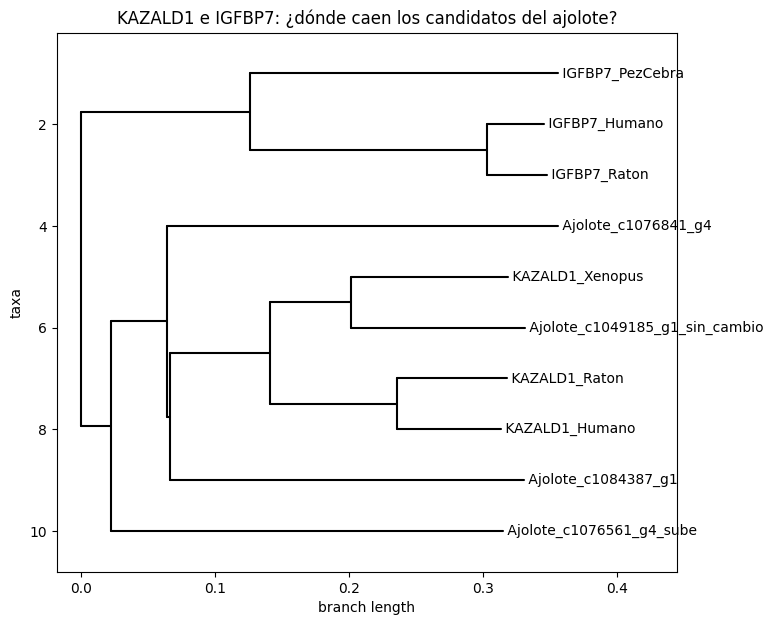

In [ ]:
"""
Celda: KAZALD1 vs IGFBP7
"""

import requests, time, subprocess, re, gzip
import numpy as np, pandas as pd
from Bio import SeqIO, AlignIO, Phylo, Align
from Bio.Align import substitution_matrices
from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceTreeConstructor
import matplotlib.pyplot as plt

salida  = "/content/drive/MyDrive/proyecto_ajolote/resultados"
destino = "/content/drive/MyDrive/proyecto_ajolote/datos"

# --- Proteínas del ajolote (por si la sesión se reinició) ---
if "prot" not in globals():
    prot = {}
    with gzip.open(f"{destino}/Axolotl.Trinity.CellReports2017.transdecoder.pep.gz", "rt") as f:
        nombre, tipo, seq = None, None, []
        for linea in f:
            if linea.startswith(">"):
                if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)
                nombre = linea[1:].split()[0]
                m = re.search(r"type:(\w+)", linea); tipo = m.group(1) if m else "NA"
                seq = []
            else:
                seq.append(linea.strip())
        if nombre: prot[nombre] = ("".join(seq).replace("*", ""), tipo)

def por_mid(mid):
    for k, (s, t) in prot.items():
        if k.endswith("|" + mid): return s
    raise KeyError(mid)

# --- Descargar IGFBP7 de cada especie ---
URL = "https://rest.uniprot.org/uniprotkb/search"
def uniprot(gen, taxid):
    for filtro in [" AND (reviewed:true)", ""]:
        q = f"(gene_exact:{gen}) AND (organism_id:{taxid}){filtro}"
        for i in range(5):
            r = requests.get(URL, params={"query": q, "format": "fasta", "size": 1}, timeout=60)
            if r.status_code == 429:
                time.sleep(5 * (i + 1)); continue
            r.raise_for_status(); break
        if r.text.strip():
            lineas = r.text.strip().split("\n")
            return lineas[0], "".join(lineas[1:])
        time.sleep(1)
    return None, None

especies = {"Humano": 9606, "Raton": 10090, "PezCebra": 7955, "Xenopus": 8364}
igfbp7 = {}
for esp, tx in especies.items():
    cab, s = uniprot("IGFBP7", tx)
    print(f"IGFBP7 {esp:9s}", (cab[:75], len(s)) if s else "NO ENCONTRADO")
    if s: igfbp7[esp] = s

# --- Identidad de cada candidato vs KAZALD1 humano y vs IGFBP7 humano ---
al = Align.PairwiseAligner()
al.substitution_matrix = substitution_matrices.load("BLOSUM62")
al.open_gap_score, al.extend_gap_score = -10, -0.5
al.end_insertion_score = al.end_deletion_score = 0

def ident(ref, sec):
    a = al.align(ref, sec)[0]; cols = mt = 0
    for (t0, t1), (q0, q1) in zip(*a.aligned):
        for x, y in zip(ref[t0:t1], sec[q0:q1]):
            cols += 1; mt += (x == y)
    return 100 * mt / cols if cols else np.nan

kaz = {r.id.split("|")[0]: str(r.seq) for r in SeqIO.parse(f"{salida}/fasta/KAZALD1_ortologos.fasta", "fasta")}
cands = {"c1076561_g4_sube": "m.178512", "c1049185_g1_sin_cambio": "m.90498",
         "c1084387_g1": "m.240218", "c1076841_g4": "m.180417"}

print("\n=== Candidatos del ajolote: ¿KAZALD1 o IGFBP7? ===")
for nom, mid in cands.items():
    s = por_mid(mid)
    ik, ii = ident(kaz["Humano"], s), ident(igfbp7["Humano"], s)
    print(f"  {nom:26s} vs KAZALD1 {ik:5.1f}%   vs IGFBP7 {ii:5.1f}%   -> {'KAZALD1' if ik > ii else 'IGFBP7'}")

# --- Árbol con las dos familias ---
secs = {}
for e, s in kaz.items():     secs[f"KAZALD1_{e}"] = s
for e, s in igfbp7.items():  secs[f"IGFBP7_{e}"] = s
for nom, mid in cands.items(): secs["Ajolote_" + nom] = por_mid(mid)

ent = f"{salida}/final/KAZALD1_IGFBP7.fasta"
with open(ent, "w") as f:
    for n, s in secs.items(): f.write(f">{n}\n{s}\n")
ali = f"{salida}/final/KAZALD1_IGFBP7_alineado.fasta"
with open(ali, "w") as out:
    subprocess.run(["mafft", "--auto", "--quiet", ent], stdout=out, check=True)

aln = AlignIO.read(ali, "fasta")
dm = DistanceCalculator("blosum62").get_distance(aln)
arbol = DistanceTreeConstructor().nj(dm)
arbol.root_at_midpoint()
fig, ax = plt.subplots(figsize=(8, 7))
Phylo.draw(arbol, axes=ax, do_show=False,
           label_func=lambda c: c.name if c.is_terminal() else None)
ax.set_title("KAZALD1 e IGFBP7: ¿dónde caen los candidatos del ajolote?")
plt.savefig(f"{salida}/08_arbol_KAZALD1_IGFBP7.png", dpi=300, bbox_inches="tight")
plt.show()



In [ ]:
# columnas

import pandas as pd

destino = "/content/drive/MyDrive/proyecto_ajolote/datos"
tn = pd.read_csv(f"{destino}/Axolotl.Trinity.CellReports2017.Trinotate.xls.gz",
                 sep="\t", compression="gzip", low_memory=False)
print(tn.columns.tolist())

gcol = tn.columns[0]                      # columna del ID del gen de Trinity
sub = tn[tn[gcol] == "c1076561_g4"]
print(len(sub), "filas para c1076561_g4")

cols = [c for c in tn.columns if any(k in c for k in
        ["transcript_id", "sprot_Top_BLASTX_hit", "sprot_Top_BLASTP_hit", "Pfam", "SignalP"])]
pd.set_option("display.max_colwidth", 140)
print(sub[cols].to_string(index=False))

['#gene_id', 'transcript_id', 'Top_BLASTX_hit', 'RNAMMER', 'prot_id', 'prot_coords', 'Top_BLASTP_hit', 'Pfam', 'SignalP', 'TmHMM', 'eggnog', 'gene_ontology', 'transcript', 'peptide']
3 filas para c1076561_g4
 transcript_id                                                                                                                                                                                                                                                                                                                                                             Pfam             SignalP
c1076561_g4_i1 PF00219.13^IGFBP^Insulin-like growth factor binding protein^43-100^E:3e-07`PF00050.16^Kazal_1^Kazal-type serine protease inhibitor domain^117-159^E:5e-08`PF07648.10^Kazal_2^Kazal-type serine protease inhibitor domain^118-159^E:6.4e-05`PF07679.11^I-set^Immunoglobulin I-set domain^163-261^E:1.5e-12`PF13895.1^Ig_2^Immunoglobulin domain^175-261^E:4.7e-08 sigP:1^23^0.808^YES
c1076561_g4_i2  